## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.25s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attin 1.2 [6c6f42d8|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attin 1.2 [6c6f42d8|fa6007dd3ce42e6d]'
00: =====================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin 0a53a9bd/.
00: Launching 'AEC train_vol_vol_attin 1.2 [6c6f42d8|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 128 for valuation.
01:   This model has 47665 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_attin' epoch 1/1000 error avg trn 642.4; val 52.17/70.44 [37s 0.67s 0.17s]. LR: 1.00e-03, GN 7.717, excess_weighted: 0.003618/0.003422, excess_weighted_avg: 0.00406/0.00354, excess_spread: 56.09/70.92, excess_spread_avg: 52.66/70.92, excess: 0

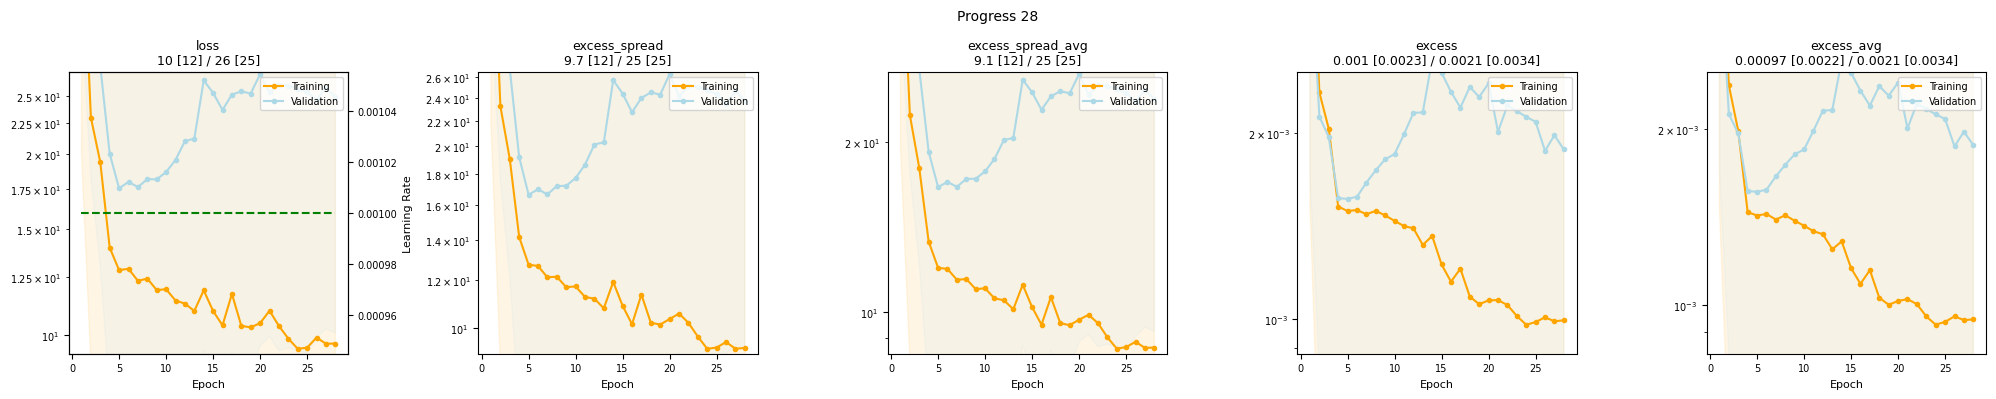

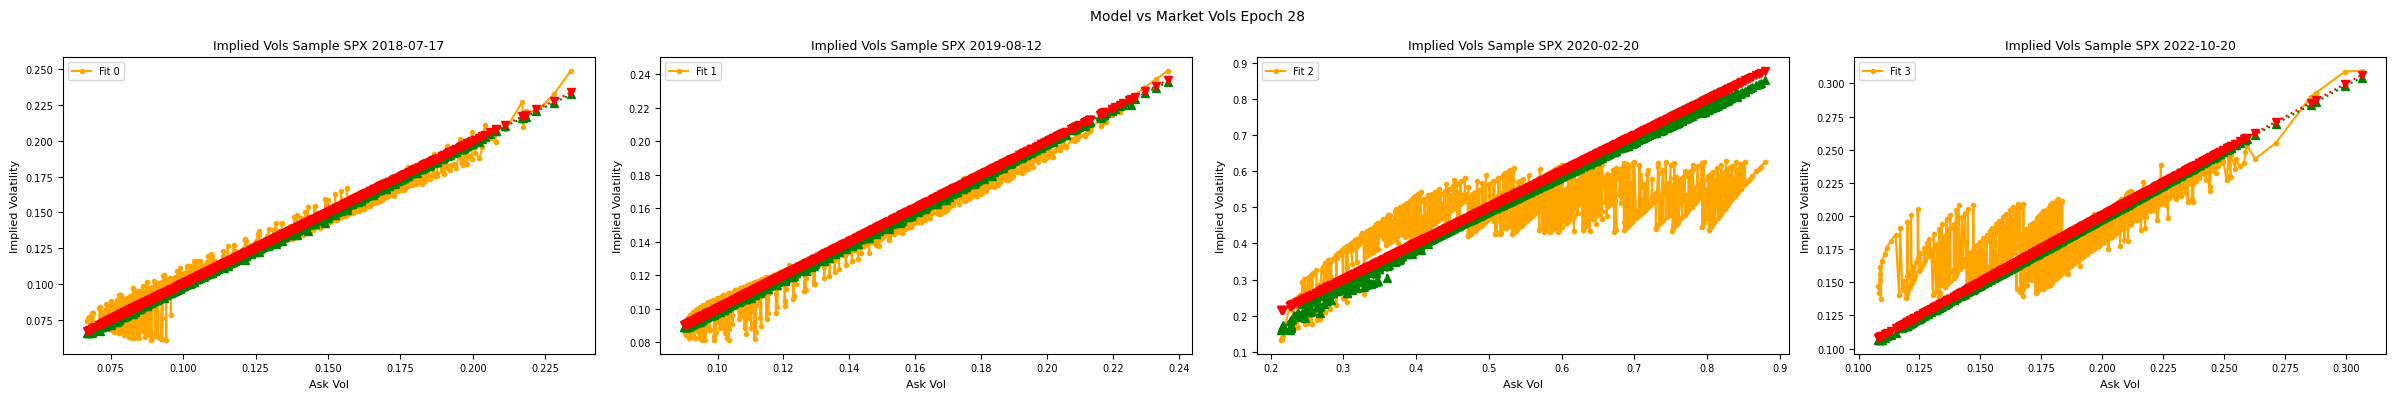

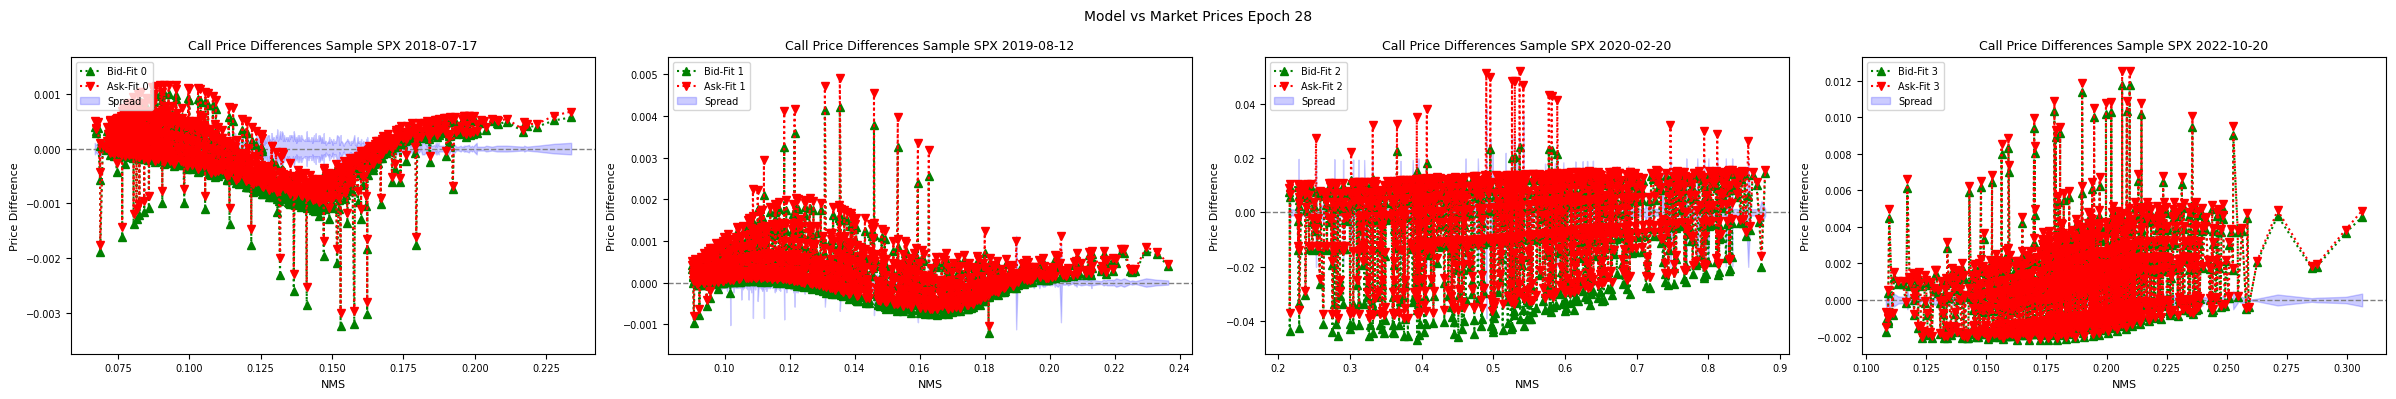

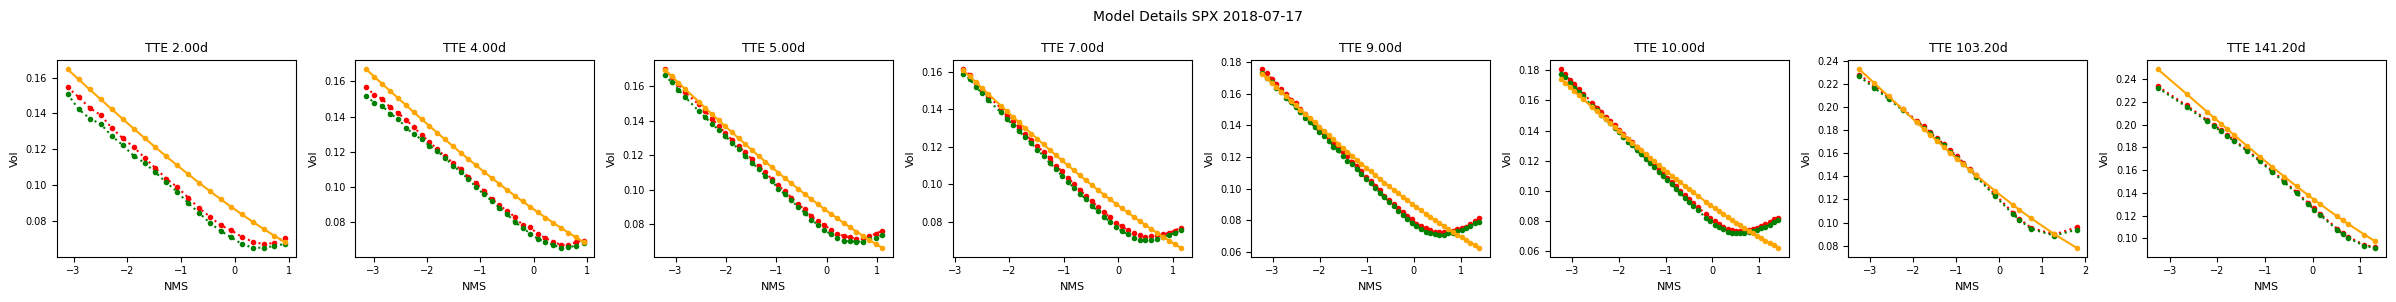

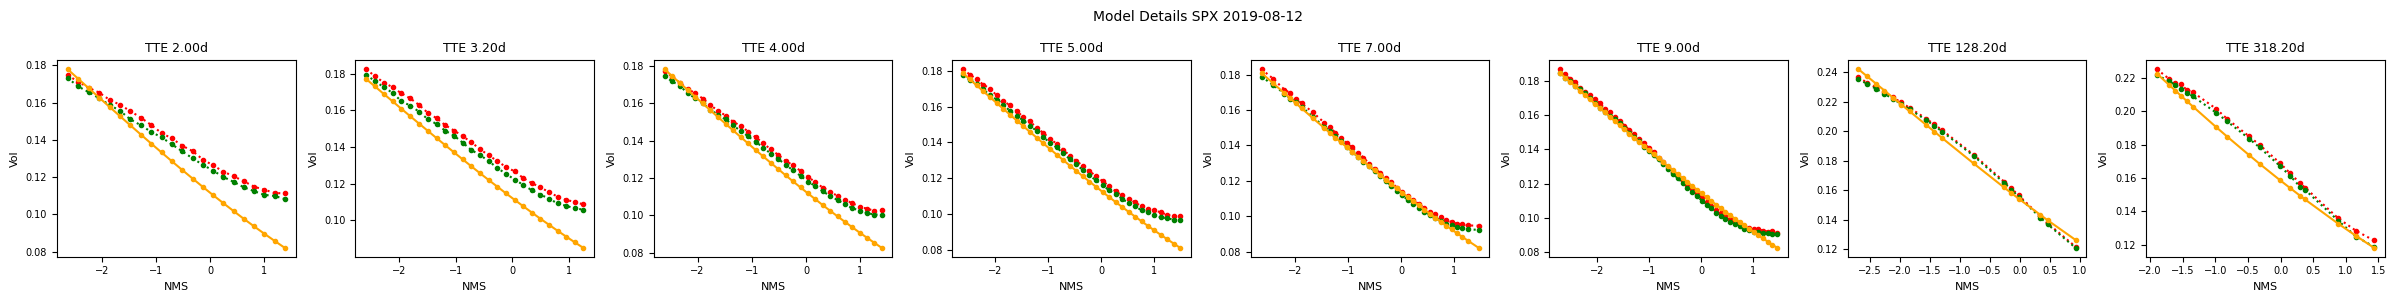

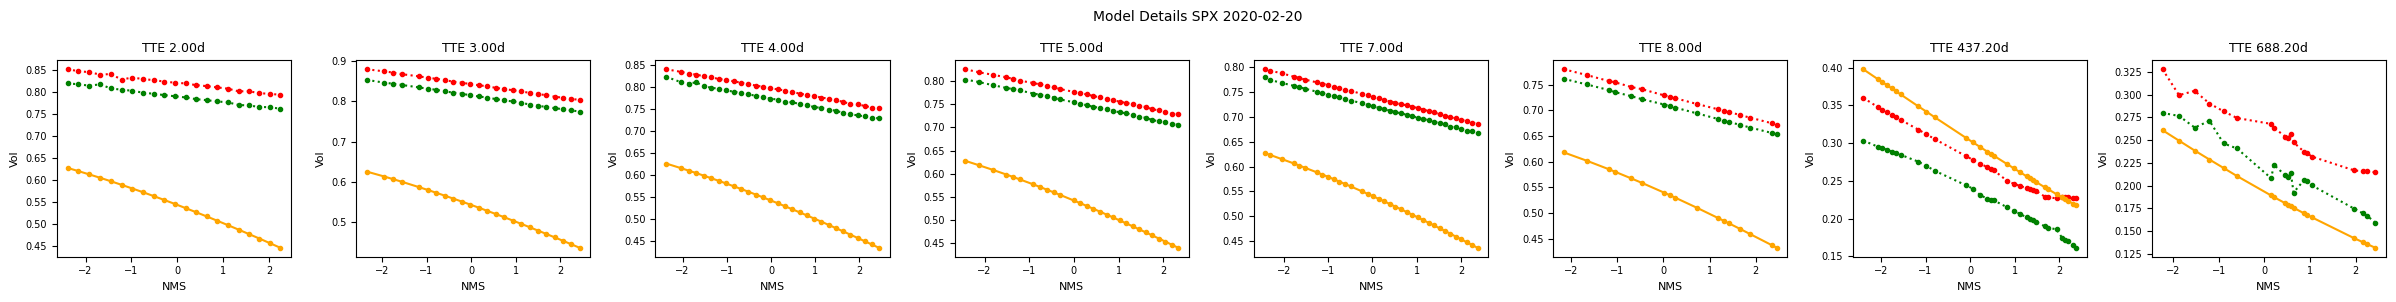

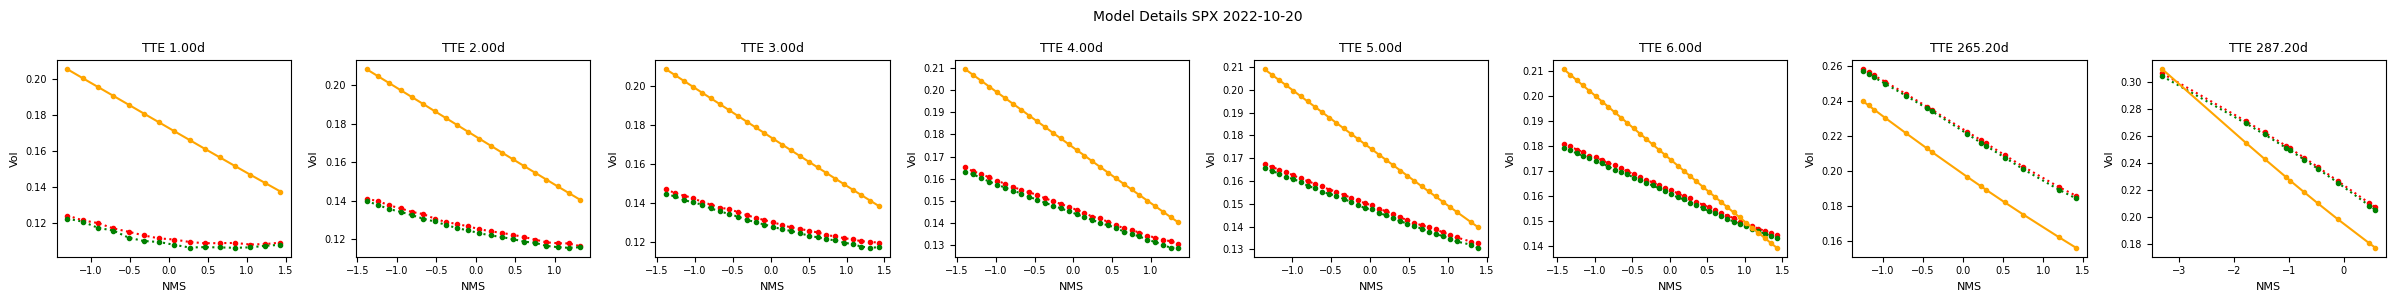

00: Training 'train_vol_vol_attin' epoch 2/1000 error avg trn 52.94; val 23/39.33 [1:14 0.67s 0.17s]. LR: 1.00e-03, GN 59.11, excess_weighted: 0.001502/0.001876, excess_weighted_avg: 0.00178/0.0019, excess_spread: 23.3/38.88, excess_spread_avg: 22.28/38.88, excess: 0.002324/0.002125, excess_avg: 0.002378/0.002125. ETA: 21:54:01.
00: Training 'train_vol_vol_attin' epoch 3/1000 error avg trn 23.61; val 19.38/28.03 [1:51 0.67s 0.17s]. LR: 1.00e-03, GN 130.5, excess_weighted: 0.001229/0.001296, excess_weighted_avg: 0.001359/0.00146, excess_spread: 19.05/26.86, excess_spread_avg: 17.96/26.86, excess: 0.002031/0.001969, excess_avg: 0.001988/0.001969. ETA: 32:57:23.
01:   Epoch 3: Saving new best validation loss 28.03 vs. 70.44 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin 0a53a9bd/best.pt'... done; this took 0.02s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )
